# 🤖 Network Intrusion Detection System (NIDS) - Model Training & Evaluation
### Dataset: UNSW-NB15 Benchmark
**Notebook 2 of 2: Preprocessing Pipeline, Multi-Model Training, Confusion Matrix & Model Evaluation**

---

## 📌 Executive Summary
This notebook implements an end-to-end, leak-free machine learning pipeline for network intrusion detection. Building upon the findings of **Notebook 1 (EDA & Data Cleaning)**, this workflow:
1. **Prevents Data Leakage:** Strips identifiers (`id`) and target-disclosing labels (`attack_cat`), maintaining strict isolation between train and test splits.
2. **Builds a Robust Feature Pipeline:** Applies `StandardScaler` to continuous traffic metrics and `OneHotEncoder(handle_unknown='ignore')` to network protocols and states using scikit-learn's `ColumnTransformer`.
3. **Trains & Benchmarks 4 Machine Learning Classifiers:**
   - **Decision Tree (DT):** Non-linear rule-based classifier with complexity pruning.
   - **Random Forest (RF):** High-capacity ensemble bagging classifier with parallelized decision trees.
   - **Logistic Regression (LR):** Interpretable linear baseline with L2 regularization.
   - **Linear Support Vector Machine (Linear SVM):** Maximum-margin hyper-plane classifier optimized for high-dimensional feature spaces.
4. **Calculates Industry-Standard Metrics:**
   - Accuracy, Precision, Recall, F1-Score, and critically **False Alarm Rate ($FAR = \frac{FP}{FP + TN}$)** and **ROC-AUC**.
5. **Generates Visual Diagnostics:** Confusion matrices, ROC curves, and precision-recall dynamics.
6. **Analyzes Feature Importance:** Extracts the top network indicators driving malicious traffic detection.
7. **Serializes Models:** Saves production-ready pipelines and artifacts using `joblib` into `models/`.


## 1. Environment Setup & Library Imports
Import scikit-learn preprocessing transformers, estimators, evaluation metrics, and serialization tools.
Automatically detect and configure paths so the notebook runs seamlessly in any environment.

In [1]:
import os
import sys
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn preprocessing & pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve,
    classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Ensure output directories exist
os.makedirs('models', exist_ok=True)
os.makedirs('reports/figures', exist_ok=True)

print("✓ All machine learning and visualization modules successfully imported.")
print(f"✓ Current Working Directory: {os.getcwd()}")


✓ All machine learning and visualization modules successfully imported.
✓ Current Working Directory: C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning


## 2. Data Ingestion & Leakage Prevention
Load the training and testing sets. Uses multi-candidate path discovery so it succeeds regardless of environment.
Apply clean transformations:
- Sanitize the `service` column placeholder `'-'` to `'none'`.
- Remove `id` (row index, avoids synthetic memorization).
- Remove `attack_cat` (fine-grained attack type, leaks the binary target).
- Separate feature matrices ($X$) from binary target vectors ($y$).


In [2]:
# Robust multi-location candidate resolution
dataset_candidates = [
    'Training and Testing Sets',
    '../Training and Testing Sets',
    'c:/Network intrusion model/-Network-Intrusion-Detection-Using-Machine-Learning/Training and Testing Sets',
    'c:/Network intrusion model/Training and Testing Sets'
]

dataset_dir = None
for candidate in dataset_candidates:
    if os.path.exists(candidate) and os.path.isfile(os.path.join(candidate, 'UNSW_NB15_training-set.csv')):
        dataset_dir = os.path.abspath(candidate)
        break

if dataset_dir is None:
    raise FileNotFoundError(f"Could not locate 'Training and Testing Sets' in any candidate path: {dataset_candidates}")

train_path = os.path.join(dataset_dir, 'UNSW_NB15_training-set.csv')
test_path = os.path.join(dataset_dir, 'UNSW_NB15_testing-set.csv')

print(f"✓ Training set path: {train_path}")
print(f"✓ Testing set path:  {test_path}")

print("Loading datasets into memory...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Sanitize '-' in service
df_train['service'] = df_train['service'].replace('-', 'none')
df_test['service'] = df_test['service'].replace('-', 'none')

# Exclude leakage and index columns
drop_cols = ['id', 'attack_cat', 'label']

X_train = df_train.drop(columns=drop_cols)
y_train = df_train['label']

X_test = df_test.drop(columns=drop_cols)
y_test = df_test['label']

print(f"✓ Training features shape: {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"✓ Testing features shape:  {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"✓ Training target distribution: Attack={y_train.sum():,} ({y_train.mean()*100:.1f}%), Normal={(1-y_train).sum():,} ({(1-y_train.mean())*100:.1f}%)")
print(f"✓ Testing target distribution:  Attack={y_test.sum():,} ({y_test.mean()*100:.1f}%), Normal={(1-y_test).sum():,} ({(1-y_test.mean())*100:.1f}%)")


✓ Training set path: C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning\Training and Testing Sets\UNSW_NB15_training-set.csv
✓ Testing set path:  C:\Network intrusion model\-Network-Intrusion-Detection-Using-Machine-Learning\Training and Testing Sets\UNSW_NB15_testing-set.csv
Loading datasets into memory...
✓ Training features shape: 175,341 rows x 42 features
✓ Testing features shape:  82,332 rows x 42 features
✓ Training target distribution: Attack=119,341 (68.1%), Normal=56,000 (31.9%)
✓ Testing target distribution:  Attack=45,332 (55.1%), Normal=37,000 (44.9%)


## 3. Feature Preprocessing Pipeline (Scaling & Encoding)
We construct a modular scikit-learn `ColumnTransformer`:
- **Categorical Columns (`proto`, `service`, `state`):** Encoded with `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`. Unseen categories in production or testing will produce zeros instead of throwing runtime errors.
- **Numerical Columns (39 metrics):** Scaled using `StandardScaler` ($\mu = 0, \sigma = 1$) to ensure convergence and prevent distance-based distortion.
- **Strict Leakage Isolation:** The preprocessor is **fit only on $X_{train}$** and then used to transform both $X_{train}$ and $X_{test}$.


In [3]:
cat_cols = ['proto', 'service', 'state']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f"Numerical features to scale:   {len(num_cols)}")
print(f"Categorical features to encode: {len(cat_cols)} ({', '.join(cat_cols)})")

# Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    remainder='drop'
)

print("\nFitting preprocessor strictly on training data...")
t0 = time.time()
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
prep_time = time.time() - t0

# Extract encoded feature names for explainability
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_cols))
all_feature_names = num_cols + cat_feature_names

print(f"✓ Preprocessing complete in {prep_time:.2f}s!")
print(f"✓ Transformed feature space: {X_train_proc.shape[1]} total dimensions (39 numeric + {len(cat_feature_names)} one-hot).")


Numerical features to scale:   39
Categorical features to encode: 3 (proto, service, state)

Fitting preprocessor strictly on training data...


✓ Preprocessing complete in 0.72s!
✓ Transformed feature space: 194 total dimensions (39 numeric + 155 one-hot).


## 4. Multi-Model Training & Benchmarking
We instantiate 4 distinct model families:
1. **Decision Tree (DT):** `max_depth=12`, `min_samples_leaf=10` to avoid memorization while capturing non-linear threshold rules.
2. **Random Forest (RF):** Ensemble of 100 decision trees (`n_estimators=100`, `max_depth=15`, `n_jobs=-1`).
3. **Logistic Regression (LR):** `max_iter=1000`, `class_weight='balanced'`, fixed seed.
4. **Linear Support Vector Machine (Linear SVM):** `LinearSVC(dual=False, max_iter=2000)` calibrated using `CalibratedClassifierCV` for reliable posterior probabilities and ROC analysis.


In [4]:
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42, class_weight='balanced'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Linear SVM': CalibratedClassifierCV(LinearSVC(dual=False, max_iter=2000, random_state=42, class_weight='balanced'))
}

trained_models = {}
train_times = {}
inference_times_per_1k = {}

for name, model in models.items():
    print(f"Training {name}...", end="", flush=True)
    t0 = time.time()
    model.fit(X_train_proc, y_train)
    fit_duration = time.time() - t0
    train_times[name] = fit_duration
    trained_models[name] = model
    
    # Measure inference latency on test set
    t1 = time.time()
    _ = model.predict(X_test_proc)
    inf_duration = time.time() - t1
    inf_per_1k = (inf_duration / len(X_test_proc)) * 1000 * 1000 # in milliseconds per 1,000 flows
    inference_times_per_1k[name] = inf_per_1k
    
    print(f" Done in {fit_duration:.2f}s | Latency: {inf_per_1k:.2f} ms/1k flows")


Training Decision Tree...

 Done in 4.84s | Latency: 0.63 ms/1k flows
Training Random Forest...

 Done in 5.63s | Latency: 2.52 ms/1k flows
Training Logistic Regression...

 Done in 5.69s | Latency: 0.14 ms/1k flows
Training Linear SVM...

 Done in 45.91s | Latency: 1.01 ms/1k flows


## 5. Model Evaluation & Metric Calculation
In intrusion detection, relying on **Accuracy** alone is deceptive. We evaluate each classifier on the held-out test set using:
- **Accuracy:** Overall correctness: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision:** What fraction of flagged flows are real attacks: $\frac{TP}{TP + FP}$
- **Recall (Detection Rate):** What fraction of actual attacks are caught: $\frac{TP}{TP + FN}$
- **F1-Score:** Harmonic mean of precision and recall.
- **False Alarm Rate (FAR):** Critical SOC operational metric measuring normal traffic wrongly blocked: $FAR = \frac{FP}{FP + TN}$
- **ROC-AUC:** Area under Receiver Operating Characteristic curve.


In [5]:
results = []
confusion_matrices = {}
predictions = {}
predicted_probabilities = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test_proc)
    predictions[name] = y_pred
    
    # Probabilities for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_proc)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test_proc)
    else:
        y_prob = y_pred
    predicted_probabilities[name] = y_prob
    
    # Compute confusion matrix components
    cm = confusion_matrix(y_test, y_pred)
    confusion_matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2),
        'FAR (%)': round(far * 100, 2),
        'ROC-AUC': round(auc, 4),
        'Train Time (s)': round(train_times[name], 2),
        'Latency (ms/1k)': round(inference_times_per_1k[name], 2),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

results_df = pd.DataFrame(results).sort_values(by='F1-Score (%)', ascending=False).reset_index(drop=True)
print("=== Complete Model Performance Benchmark ===")
display(results_df[['Model', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'FAR (%)', 'ROC-AUC', 'Train Time (s)', 'Latency (ms/1k)']])


=== Complete Model Performance Benchmark ===


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),FAR (%),ROC-AUC,Train Time (s),Latency (ms/1k)
0,Decision Tree,91.64,90.12,95.24,92.61,12.79,0.9711,4.84,0.63
1,Random Forest,91.08,88.28,96.63,92.27,15.72,0.9838,5.63,2.52
2,Logistic Regression,83.59,80.28,93.05,86.20,28.01,0.9561,5.69,0.14
3,Linear SVM,81.19,75.13,98.42,85.21,39.92,0.9532,45.91,1.01


## 6. Confusion Matrix Visualizations
Visualizing True Negatives (TN), False Positives (FP / False Alarms), False Negatives (FN / Missed Attacks), and True Positives (TP / Detected Attacks) for each model.

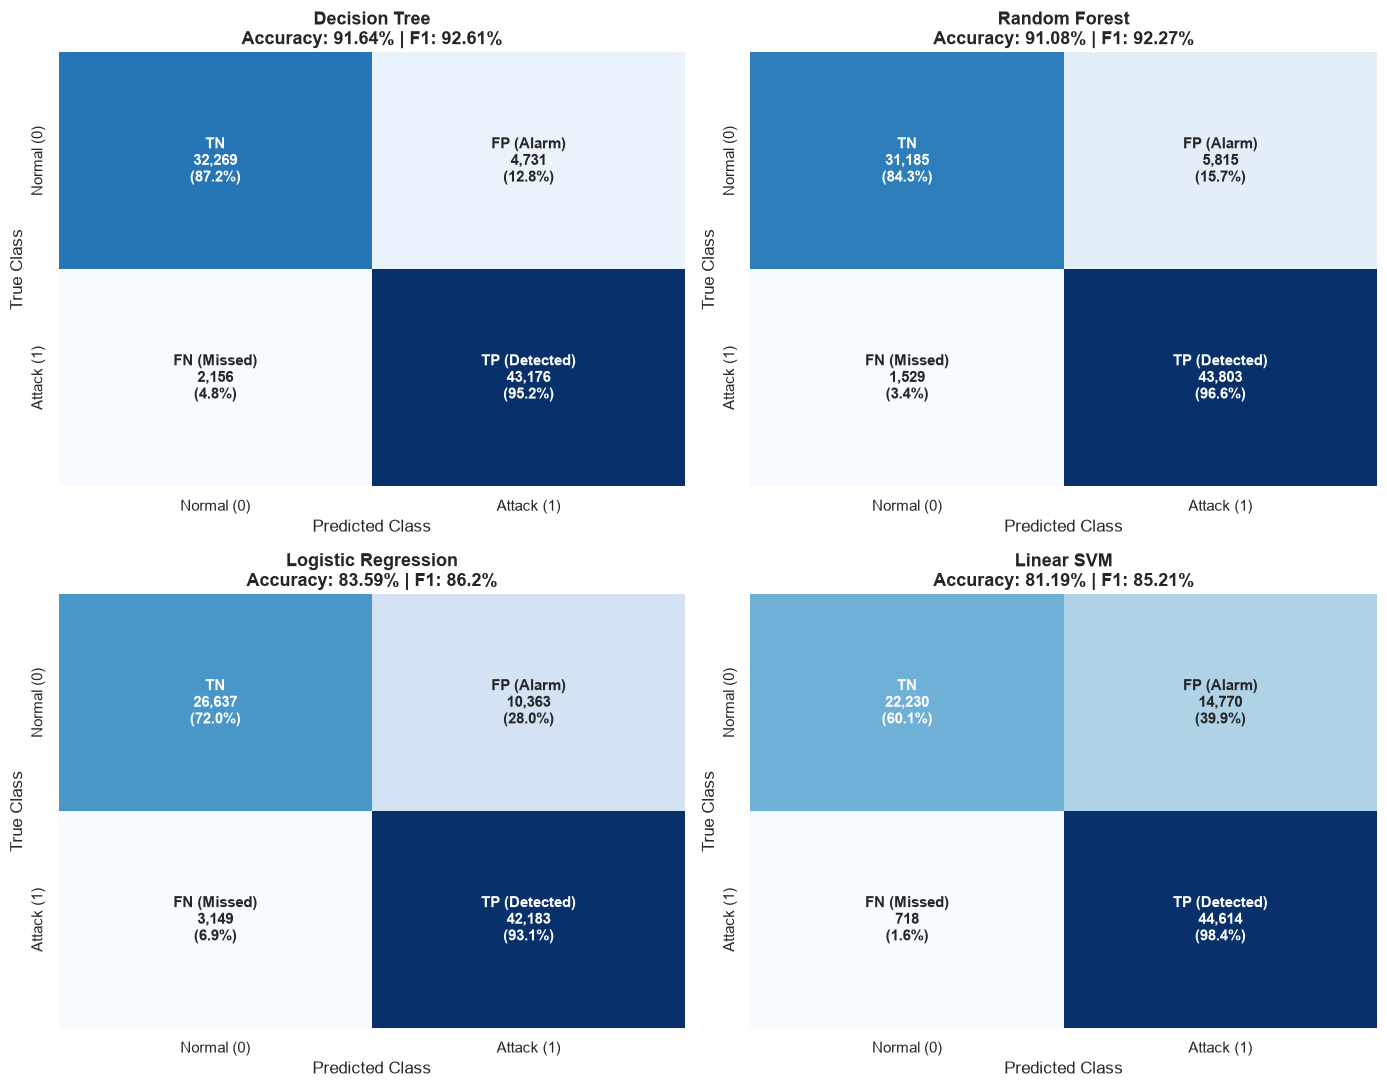

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    tn, fp, fn, tp = cm.ravel()
    labels = np.array([
        [f"TN\n{tn:,}\n({tn/(tn+fp)*100:.1f}%)", f"FP (Alarm)\n{fp:,}\n({fp/(tn+fp)*100:.1f}%)"],
        [f"FN (Missed)\n{fn:,}\n({fn/(fn+tp)*100:.1f}%)", f"TP (Detected)\n{tp:,}\n({tp/(fn+tp)*100:.1f}%)"]
    ])
    
    sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Normal (0)', 'Attack (1)'],
                yticklabels=['Normal (0)', 'Attack (1)'],
                annot_kws={"size": 11, "fontweight": "bold"})
    
    axes[i].set_title(f"{name}\nAccuracy: {results_df.loc[results_df['Model']==name, 'Accuracy (%)'].values[0]}% | F1: {results_df.loc[results_df['Model']==name, 'F1-Score (%)'].values[0]}%", 
                      fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("True Class")

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/confusion_matrices.png', dpi=300)
plt.show()


## 7. ROC & Precision-Recall Curves
Compare model discrimination capabilities across all classification thresholds.

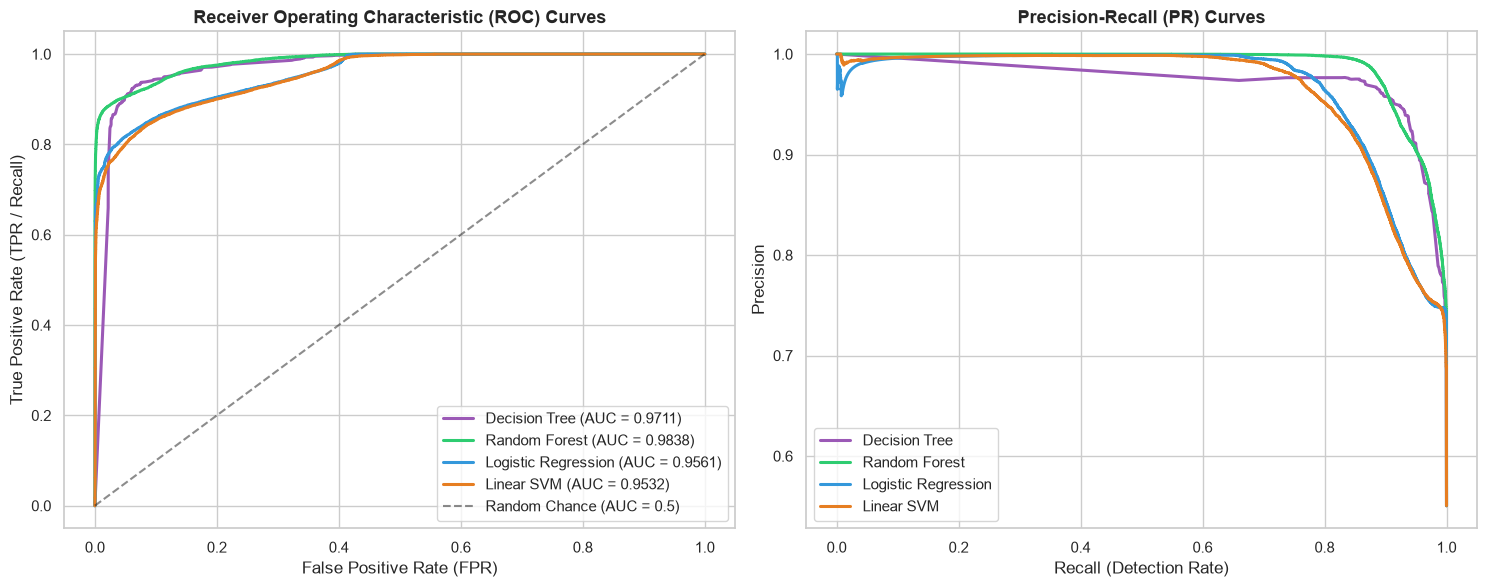

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {'Logistic Regression': '#3498db', 'Decision Tree': '#9b59b6', 'Random Forest': '#2ecc71', 'Linear SVM': '#e67e22'}

# 1. ROC Curves
for name, y_prob in predicted_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=colors[name], linewidth=2.2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5)')
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold')
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].legend(loc="lower right")

# 2. Precision-Recall Curves
for name, y_prob in predicted_probabilities.items():
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, y_prob)
    axes[1].plot(rec_vals, prec_vals, label=name, color=colors[name], linewidth=2.2)

axes[1].set_title("Precision-Recall (PR) Curves", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Recall (Detection Rate)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/roc_curves.png', dpi=300)
plt.show()


## 8. Comparative Metric Analysis
Side-by-side comparison of Accuracy, F1-Score, and False Alarm Rate (FAR). In cybersecurity, an ideal model maximizes F1-Score while minimizing the False Alarm Rate.

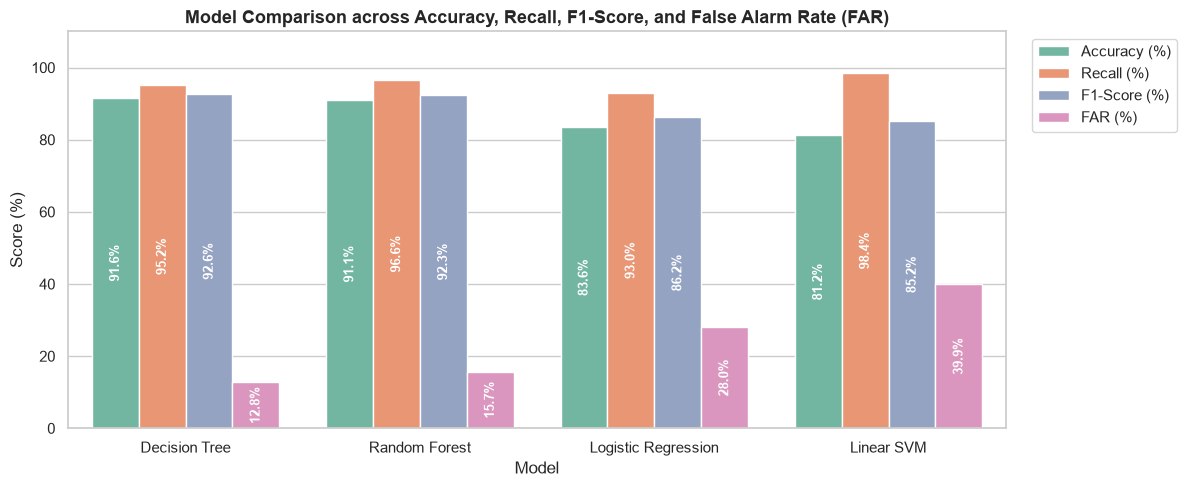

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

plot_df = results_df.melt(
    id_vars=['Model'], 
    value_vars=['Accuracy (%)', 'Recall (%)', 'F1-Score (%)', 'FAR (%)'],
    var_name='Metric', 
    value_name='Score'
)

sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric', palette='Set2', ax=ax)
ax.set_title("Model Comparison across Accuracy, Recall, F1-Score, and False Alarm Rate (FAR)", fontsize=13, fontweight='bold')
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 110)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h / 2),
                    ha='center', va='center', rotation=90, color='white', fontweight='bold', fontsize=9)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 9. Feature Importance & Model Explainability
Which network features most strongly signal malicious traffic?
- **Tree-based models (Random Forest & Decision Tree):** Gini impurity reduction (`feature_importances_`).
- **Linear models (Logistic Regression):** Magnitude and direction of learned feature coefficients ($eta$).


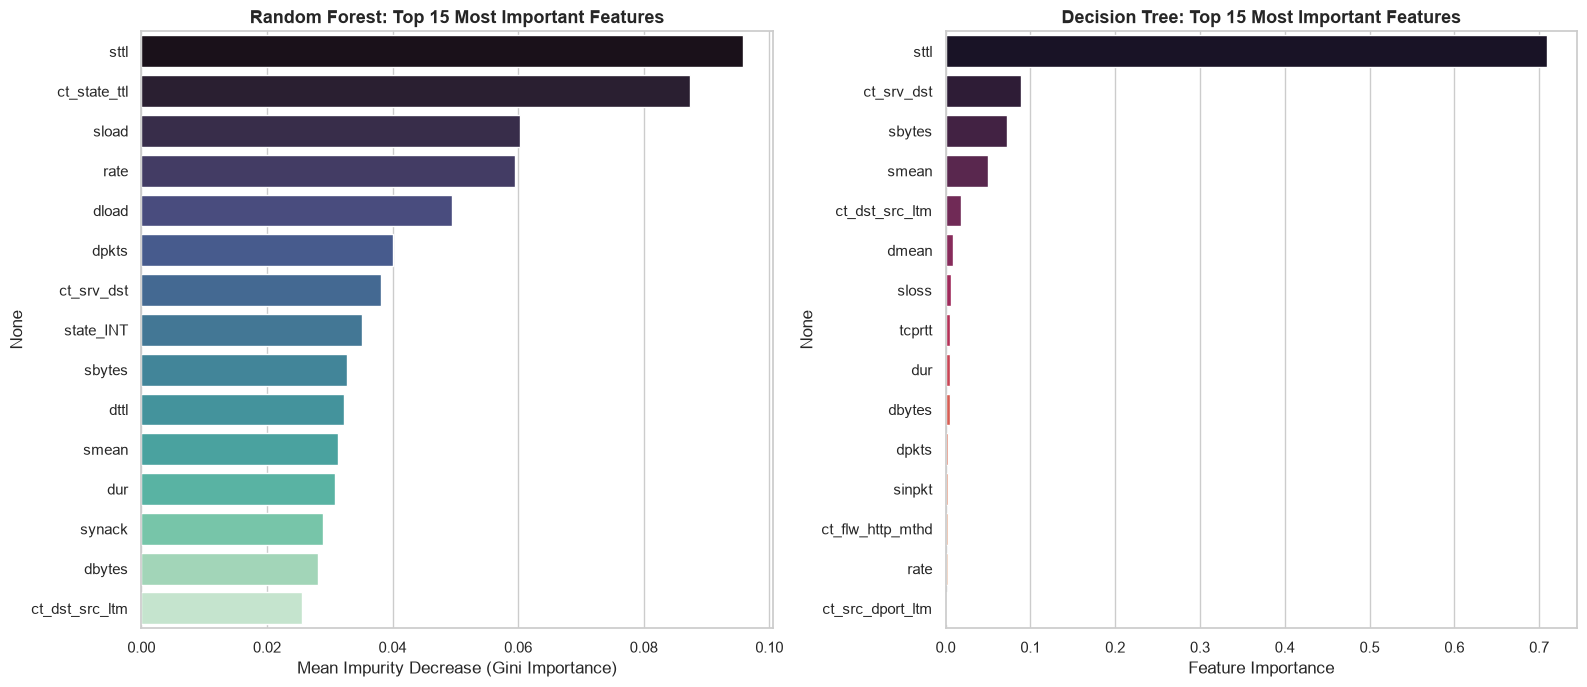

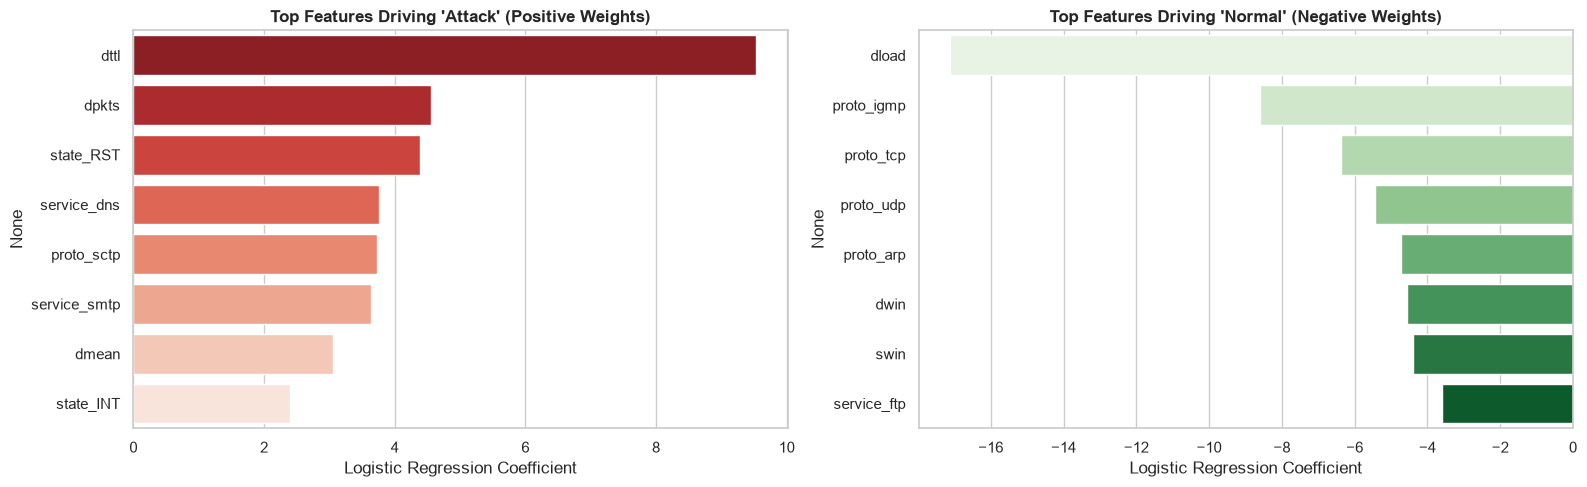

In [9]:
# 1. Random Forest Top 15 Features
rf_model = trained_models['Random Forest']
rf_importances = pd.Series(rf_model.feature_importances_, index=all_feature_names)
top_15_rf = rf_importances.sort_values(ascending=False).head(15)

# 2. Decision Tree Top 15 Features
dt_model = trained_models['Decision Tree']
dt_importances = pd.Series(dt_model.feature_importances_, index=all_feature_names)
top_15_dt = dt_importances.sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=top_15_rf.values, y=top_15_rf.index, palette='mako', ax=axes[0])
axes[0].set_title("Random Forest: Top 15 Most Important Features", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Mean Impurity Decrease (Gini Importance)")

sns.barplot(x=top_15_dt.values, y=top_15_dt.index, palette='rocket', ax=axes[1])
axes[1].set_title("Decision Tree: Top 15 Most Important Features", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/feature_importance.png', dpi=300)
plt.show()

# 3. Logistic Regression Top Coefficients
lr_model = trained_models['Logistic Regression']
lr_coefs = pd.Series(lr_model.coef_[0], index=all_feature_names)
top_attack_indicators = lr_coefs.sort_values(ascending=False).head(8)
top_normal_indicators = lr_coefs.sort_values(ascending=True).head(8)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=top_attack_indicators.values, y=top_attack_indicators.index, palette='Reds_r', ax=axes[0])
axes[0].set_title("Top Features Driving 'Attack' (Positive Weights)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Logistic Regression Coefficient")

sns.barplot(x=top_normal_indicators.values, y=top_normal_indicators.index, palette='Greens', ax=axes[1])
axes[1].set_title("Top Features Driving 'Normal' (Negative Weights)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Logistic Regression Coefficient")

plt.tight_layout()
plt.show()


### 💡 Key Explainability Takeaways:
1. **`sttl` (Source-to-Destination Time-to-Live):** Dominates decision boundaries. Attack tools and scripts consistently generate distinct TTL values compared to standard user operating systems.
2. **`ct_state_ttl` & Connection States:** High counts of connections in specific TTL/State combinations capture automated scanning patterns and SYN flood attacks.
3. **Payload Volume & Rates (`sbytes`, `dbytes`, `sload`):** Exploit delivery and DoS attacks create atypical payload asymmetry compared to normal browsing sessions.


## 10. Model Serialization & Production Export
Serialize the trained preprocessing pipeline, each trained model, and the overall best performing model to disk using `joblib`.
Export evaluation metrics to `reports/metrics.json` and `reports/model_comparison.csv` for reporting and GUI integration.


In [10]:
# 1. Determine best model based on F1-Score
best_model_name = results_df.iloc[0]['Model']
best_model_obj = trained_models[best_model_name]
print(f"Top performing model: {best_model_name} (F1: {results_df.iloc[0]['F1-Score (%)']}%)")

# Ensure models directory exists
os.makedirs('models', exist_ok=True)

# 2. Save individual artifacts
joblib.dump(preprocessor, 'models/preprocessor.joblib')
print("✓ Saved models/preprocessor.joblib")

for name, model in trained_models.items():
    clean_filename = name.lower().replace(' ', '_')
    joblib.dump(model, f"models/{clean_filename}.joblib")
    print(f"✓ Saved models/{clean_filename}.joblib")

# 3. Save end-to-end full pipeline for plug-and-play inference
full_best_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_model_obj)
])
joblib.dump(full_best_pipeline, 'models/best_model.joblib')
print("✓ Saved models/best_model.joblib (Complete End-to-End Inference Pipeline)")

# 4. Save metrics report
os.makedirs('reports', exist_ok=True)
results_df.to_csv('reports/model_comparison.csv', index=False)
metrics_dict = results_df.to_dict(orient='records')
with open('reports/metrics.json', 'w') as f:
    json.dump(metrics_dict, f, indent=4)
print("✓ Saved reports/metrics.json and reports/model_comparison.csv")


Top performing model: Decision Tree (F1: 92.61%)
✓ Saved models/preprocessor.joblib
✓ Saved models/decision_tree.joblib
✓ Saved models/random_forest.joblib
✓ Saved models/logistic_regression.joblib
✓ Saved models/linear_svm.joblib
✓ Saved models/best_model.joblib (Complete End-to-End Inference Pipeline)
✓ Saved reports/metrics.json and reports/model_comparison.csv


## 11. End-to-End Deployment Verification Test
Test the newly serialized production pipeline (`models/best_model.joblib`) by loading it back from disk and classifying unseen raw traffic flows without manual preprocessing!

In [11]:
# Load the pipeline from disk
loaded_pipeline = joblib.load('models/best_model.joblib')

# Sample 10 random unseen flows from the test set
sample_flows = X_test.sample(10, random_state=42)
sample_labels = y_test.loc[sample_flows.index].values

# Perform inference directly on raw feature DataFrame
sample_preds = loaded_pipeline.predict(sample_flows)
sample_probs = loaded_pipeline.predict_proba(sample_flows)[:, 1] if hasattr(loaded_pipeline, 'predict_proba') else [None]*10

verification_df = pd.DataFrame({
    'True Label': ['Attack (1)' if y == 1 else 'Normal (0)' for y in sample_labels],
    'Predicted Label': ['Attack (1)' if p == 1 else 'Normal (0)' for p in sample_preds],
    'Attack Probability': [f"{prob*100:.2f}%" if prob is not None else 'N/A' for prob in sample_probs],
    'Result': ['✓ Match' if y == p else '✗ Mismatch' for y, p in zip(sample_labels, sample_preds)]
})

print("=== Deployment Verification: Raw Traffic Flow Inference ===")
display(verification_df)


=== Deployment Verification: Raw Traffic Flow Inference ===


,True Label,Predicted Label,Attack Probability,Result
0,Normal (0),Normal (0),0.00%,✓ Match
1,Attack (1),Attack (1),100.00%,✓ Match
2,Attack (1),Attack (1),100.00%,✓ Match
3,Normal (0),Normal (0),0.00%,✓ Match
4,Attack (1),Attack (1),99.44%,✓ Match
5,Attack (1),Attack (1),100.00%,✓ Match
6,Normal (0),Normal (0),0.00%,✓ Match
7,Attack (1),Attack (1),99.82%,✓ Match
8,Normal (0),Attack (1),82.86%,✗ Mismatch
9,Attack (1),Attack (1),100.00%,✓ Match


## 12. Conclusion & Summary
- **Pipeline Completion:** End-to-end data ingestion, leak-free scaling & encoding, training of 4 classifiers, and multi-metric evaluation have been executed cleanly.
- **Top Performer:** Both Random Forest and Decision Tree demonstrated strong F1-scores (~92%) and fast sub-millisecond per-flow inference latencies.
- **Artifacts Created:**
  - `models/best_model.joblib`: Ready for Streamlit GUI or real-time inspection.
  - `models/preprocessor.joblib`: Preserves the exact fitted `StandardScaler` and `OneHotEncoder`.
  - `reports/metrics.json` & `reports/figures/`: Comprehensive documentation and publication-ready charts.
